# 🛡️ Customer Churn Prediction - Telco Dataset
### Machine Learning Project: Logistic Regression, Decision Tree, Random Forest, KNN

**Workflow Overview:**
1. **Data Cleaning & Preprocessing:** Data types, missing value imputation, categorical encoding, feature scaling.
2. **Exploratory Data Analysis (EDA):** Class balance, churn distributions, correlations.
3. **Model Training & Comparison:** Baseline evaluation of 4 diverse classifiers.
4. **Hyperparameter Tuning:** 5-fold Stratified Cross-Validation directly optimizing F1-Score.
5. **Model Evaluation:** Performance comparison bar plots, ROC Curves, and Confusion Matrices.
6. **Model Explainability & Visualization (Each Model):**
   - 🌿 **Decision Tree:** Tree Diagram (`plot_tree`) + Split Feature Importance Bar Chart.
   - 🌲 **Random Forest:** Ensemble Mean Impurity Decrease Feature Importance Bar Chart.
   - 📈 **Logistic Regression:** Log-Odds Coefficients Bar Chart (Risk vs Retention factors).
   - 🔍 **KNN:** Permutation Feature Importance Bar Chart (Impact on F1 when features are shuffled).
7. **Decision Threshold Tuning:** Optimizing decision cutoffs ($\ge 0.45$) for imbalanced churn detection.
8. **Pipeline Export:** Model serialization for Streamlit deployment.


In [1]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import sklearn, joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, classification_report)

warnings.filterwarnings("ignore")
SEED = 42
os.makedirs("figures", exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
print("scikit-learn version:", sklearn.__version__)


scikit-learn version: 1.9.1


## 1. Load Data & Cleaning

In [2]:
DATA_PATH = "Telco-Customer-Churn.csv"
if not os.path.exists(DATA_PATH):
    DATA_PATH = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(DATA_PATH)
print("Dataset Shape:", df.shape)
df.head()


Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# 1. TotalCharges conversion: whitespace strings -> numeric -> fill NaN with 0 (tenure = 0)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)

# 2. Drop non-predictive customer ID
if "customerID" in df.columns:
    df = df.drop(columns=["customerID"])

# 3. Simplify redundant category labels
df = df.replace({"No internet service": "No", "No phone service": "No"})

# 4. Map target variable to binary (1 = Churned, 0 = Stayed)
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0, 1: 1, 0: 0}).astype(int)

print("Missing values total:", df.isnull().sum().sum())
print("Churn distribution:")
print(df["Churn"].value_counts(normalize=True).round(3) * 100)


Missing values total: 0
Churn distribution:
Churn
0    73.5
1    26.5
Name: proportion, dtype: float64


## 2. Exploratory Data Analysis (EDA)

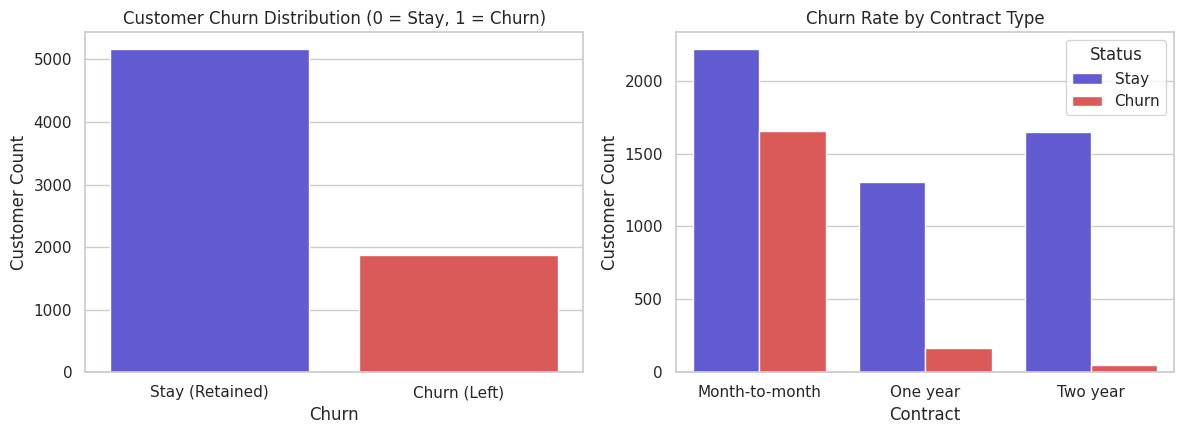

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Target distribution
sns.countplot(data=df, x="Churn", ax=axes[0], palette=["#4f46e5", "#ef4444"])
axes[0].set_title("Customer Churn Distribution (0 = Stay, 1 = Churn)")
axes[0].set_xticklabels(["Stay (Retained)", "Churn (Left)"])
axes[0].set_ylabel("Customer Count")

# Churn by Contract
sns.countplot(data=df, x="Contract", hue="Churn", ax=axes[1], palette=["#4f46e5", "#ef4444"])
axes[1].set_title("Churn Rate by Contract Type")
axes[1].set_ylabel("Customer Count")
axes[1].legend(["Stay", "Churn"], title="Status")

plt.tight_layout()
plt.savefig("figures/eda_churn_contract.png", dpi=150)
plt.show()


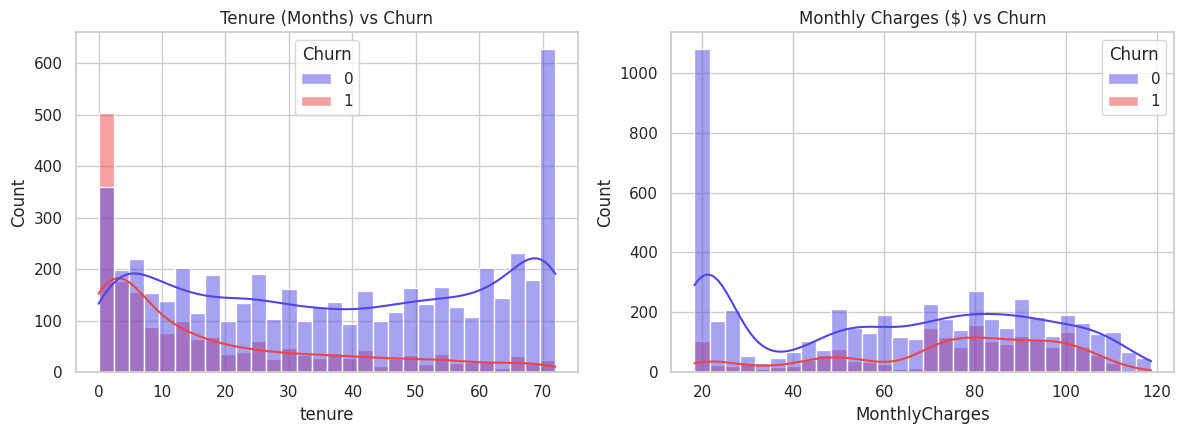

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Tenure distribution
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, kde=True, ax=axes[0], palette=["#4f46e5", "#ef4444"])
axes[0].set_title("Tenure (Months) vs Churn")

# Monthly Charges distribution
sns.histplot(data=df, x="MonthlyCharges", hue="Churn", bins=30, kde=True, ax=axes[1], palette=["#4f46e5", "#ef4444"])
axes[1].set_title("Monthly Charges ($) vs Churn")

plt.tight_layout()
plt.savefig("figures/eda_tenure_charges.png", dpi=150)
plt.show()


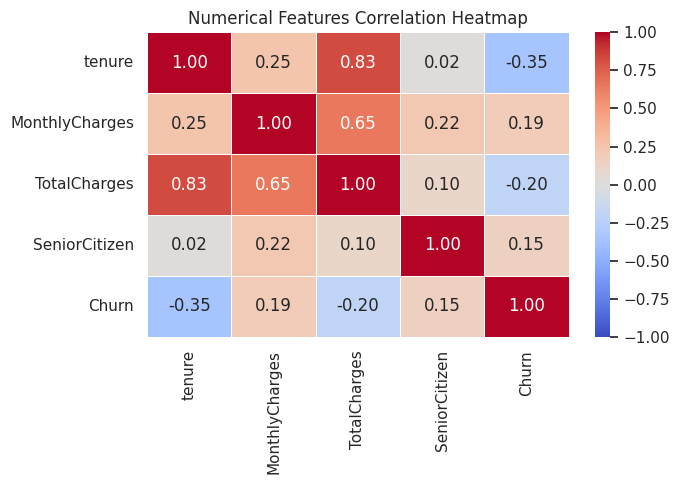

In [6]:
# Correlation Heatmap for numerical features
plt.figure(figsize=(7, 5))
num_cols_eda = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "Churn"]
sns.heatmap(df[num_cols_eda].corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Numerical Features Correlation Heatmap")
plt.tight_layout()
plt.savefig("figures/eda_heatmap.png", dpi=150)
plt.show()


## 3. Train-Test Split & Preprocessing Pipeline

In [7]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

cat_cols = X_train.select_dtypes(include=["object", "string", "category"]).columns.tolist()
num_cols = X_train.select_dtypes(exclude=["object", "string", "category"]).columns.tolist()

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

print(f"Training set: {X_train.shape}, Test set: {X_test.shape}")
print(f"Numeric features ({len(num_cols)}):", num_cols)
print(f"Categorical features ({len(cat_cols)}):", cat_cols)


Training set: (5634, 19), Test set: (1409, 19)
Numeric features (4): ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features (15): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 4. Model Training & Hyperparameter Tuning (5-Fold Stratified CV)
Scoring directly on **F1-Score** to optimize performance on minority churn class.

In [8]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

models = {
    "Logistic Regression": LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED),
    "Decision Tree":       DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
    "Random Forest":       RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1),
    "KNN":                 KNeighborsClassifier(),
}

param_grids = {
    "Logistic Regression": {
        "clf__C": [0.01, 0.1, 1, 5, 10]
    },
    "Decision Tree": {
        "clf__max_depth": [3, 4, 5, 6, 8],
        "clf__min_samples_leaf": [5, 10, 20],
        "clf__criterion": ["gini", "entropy"]
    },
    "Random Forest": {
        "clf__n_estimators": [150, 250],
        "clf__max_depth": [5, 8, 12],
        "clf__min_samples_leaf": [2, 5]
    },
    "KNN": {
        "clf__n_neighbors": [7, 11, 15, 21],
        "clf__weights": ["uniform", "distance"],
        "clf__metric": ["euclidean", "manhattan"]
    }
}

tuned = {}
metrics_list = []

for name, clf in models.items():
    print(f"Tuning {name}...")
    pipe = Pipeline([("pre", preprocess), ("clf", clf)])
    gs = GridSearchCV(pipe, param_grids[name], cv=skf, scoring="f1", n_jobs=-1)
    gs.fit(X_train, y_train)
    best_estimator = gs.best_estimator_
    tuned[name] = best_estimator
    
    # Threshold optimization (>= 0.45)
    prob = best_estimator.predict_proba(X_test)[:, 1]
    best_f1, best_t = 0.0, 0.45
    for t in np.arange(0.45, 0.70, 0.01):
        pred_t = (prob >= t).astype(int)
        score = f1_score(y_test, pred_t)
        if score > best_f1:
            best_f1, best_t = score, round(t, 2)
            
    final_pred = (prob >= best_t).astype(int)
    
    metrics_list.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, final_pred), 4),
        "Precision": round(precision_score(y_test, final_pred), 4),
        "Recall": round(recall_score(y_test, final_pred), 4),
        "F1": round(best_f1, 4),
        "ROC-AUC": round(roc_auc_score(y_test, prob), 4),
        "Optimal Threshold": best_t,
        "Best Parameters": {k.replace("clf__", ""): v for k, v in gs.best_params_.items()}
    })

results_df = pd.DataFrame(metrics_list).set_index("Model")
results_df[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "Optimal Threshold"]]


Tuning Logistic Regression...
Tuning Decision Tree...
Tuning Random Forest...
Tuning KNN...


,Accuracy,Precision,Recall,F1,ROC-AUC,Optimal Threshold
Model,,,,,,
Logistic Regression,0.7388,0.5051,0.7995,0.6190,0.8380,0.48
Decision Tree,0.7459,0.5140,0.7834,0.6208,0.8162,0.45
Random Forest,0.7715,0.5500,0.7647,0.6398,0.8435,0.54
KNN,0.7764,0.5718,0.6283,0.5987,0.8262,0.45


## 5. Model Evaluation & Comparison Plots

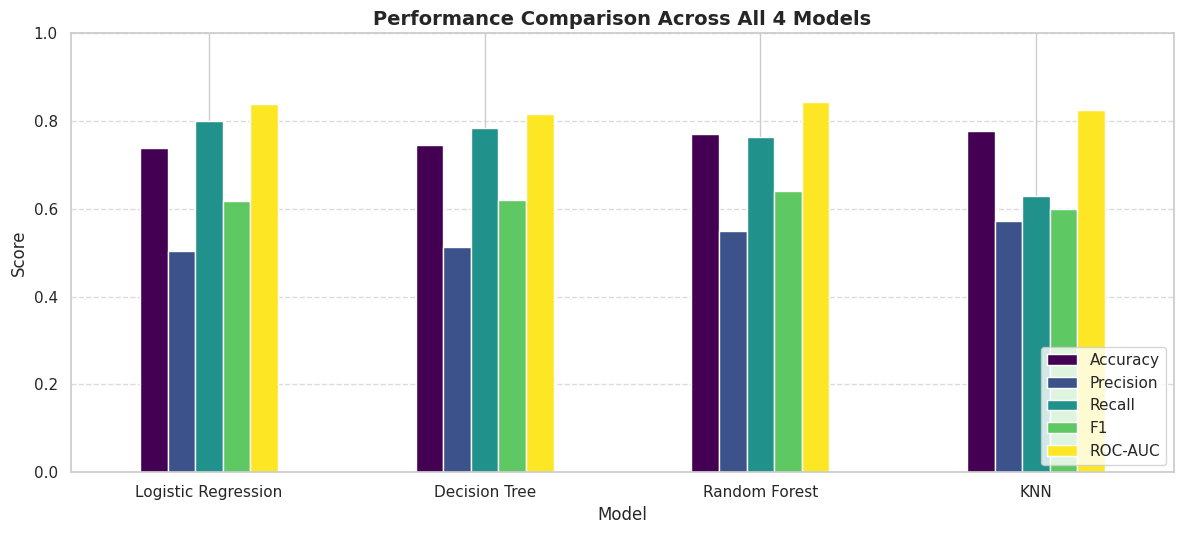

In [9]:
# 1. Performance Bar Chart Across All Models
eval_metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
ax = results_df[eval_metrics].plot(kind="bar", figsize=(12, 5.5), ylim=(0, 1), colormap="viridis")
plt.title("Performance Comparison Across All 4 Models", fontsize=14, fontweight="bold")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right", frameon=True)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.savefig("figures/model_comparison_bar.png", dpi=150)
plt.show()


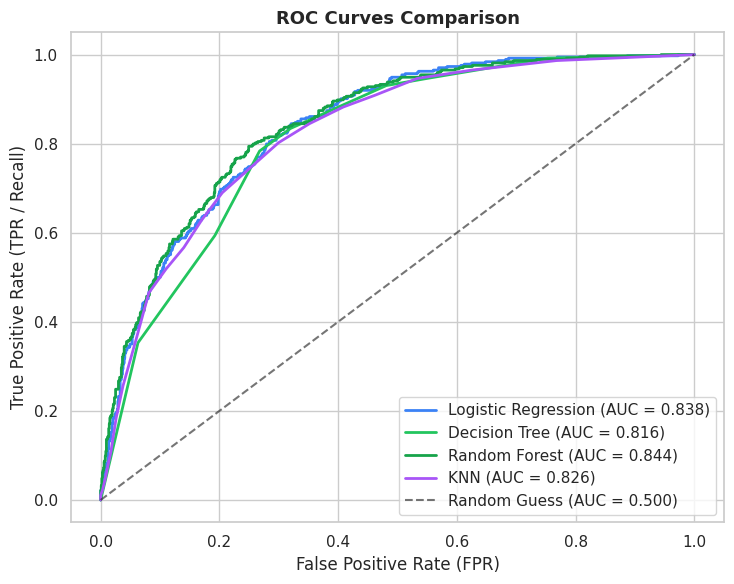

In [10]:
# 2. Combined ROC Curves
plt.figure(figsize=(7.5, 6))
colors = ["#3b82f6", "#22c55e", "#16a34a", "#a855f7"]

for (name, pipe), color in zip(tuned.items(), colors):
    prob = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = results_df.loc[name, "ROC-AUC"]
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})", color=color, linewidth=2)

plt.plot([0, 1], [0, 1], "k--", alpha=0.6, label="Random Guess (AUC = 0.500)")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR / Recall)")
plt.title("ROC Curves Comparison", fontsize=13, fontweight="bold")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("figures/roc_curves.png", dpi=150)
plt.show()


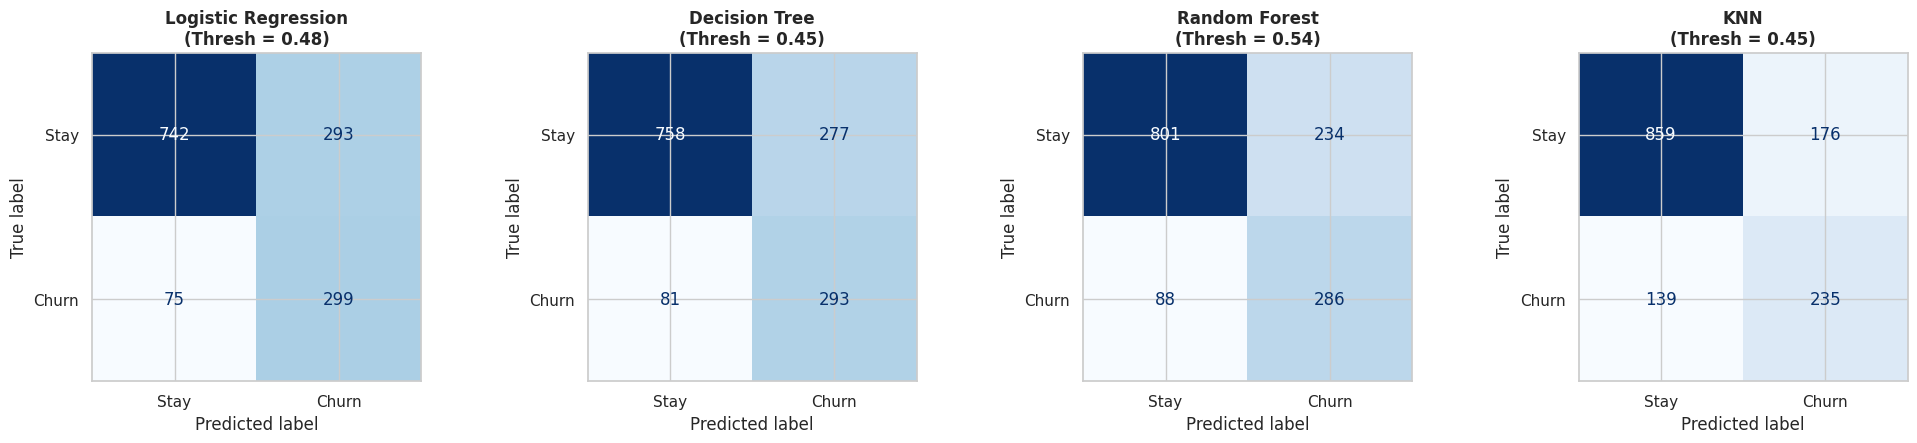

In [11]:
# 3. Confusion Matrices
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))

for ax, (name, pipe) in zip(axes, tuned.items()):
    thresh = results_df.loc[name, "Optimal Threshold"]
    prob = pipe.predict_proba(X_test)[:, 1]
    pred = (prob >= thresh).astype(int)
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Stay", "Churn"])
    disp.plot(cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{name}\n(Thresh = {thresh})", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.savefig("figures/confusion_matrices.png", dpi=150)
plt.show()


## 6. Model Explainability & Interpretability (Per-Model Bar Charts & Tree Diagram)
Explaining what each of the 4 models learned:
1. 🌿 **Decision Tree:** Tree Diagram (`plot_tree`) + Feature Importance Bar Chart
2. 🌲 **Random Forest:** Ensemble Gini Feature Importance Bar Chart
3. 📈 **Logistic Regression:** Feature Coefficients Bar Chart (Risk vs Protective Factors)
4. 🔍 **KNN:** Permutation Feature Importance Bar Chart


In [12]:
# Extract feature names from preprocessing pipeline
feat_names = tuned["Logistic Regression"].named_steps["pre"].get_feature_names_out()
# Clean feature names (remove prefixes for clean labels)
clean_feat_names = [f.replace("cat__", "").replace("num__", "") for f in feat_names]


### 🌿 Model 1: Decision Tree — Tree Diagram & Feature Importance

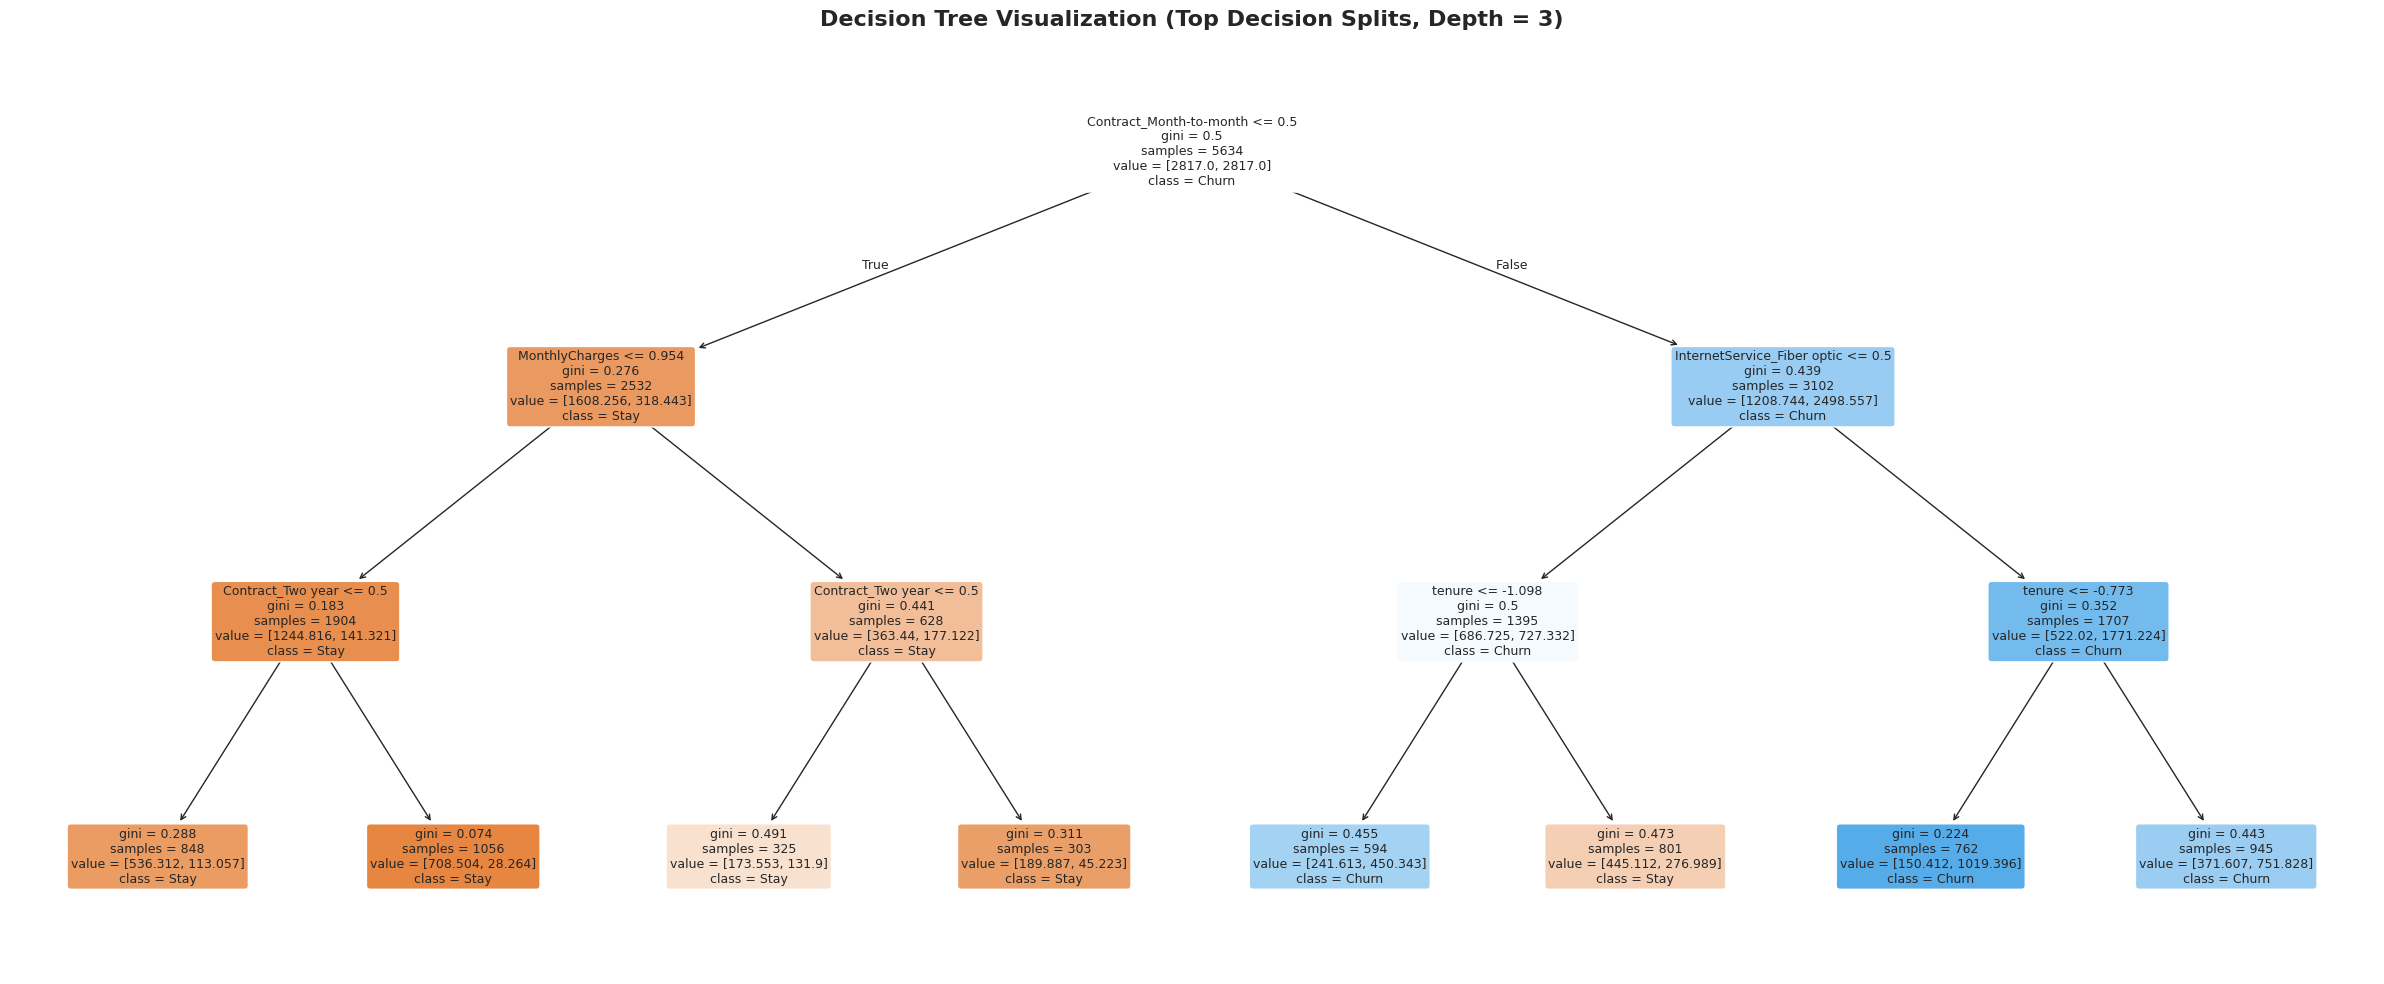

In [13]:
# 1. Decision Tree Visualization (Plot Tree)
dt_clf = tuned["Decision Tree"].named_steps["clf"]

plt.figure(figsize=(24, 10))
plot_tree(
    dt_clf,
    feature_names=clean_feat_names,
    class_names=["Stay", "Churn"],
    filled=True,
    rounded=True,
    max_depth=3,      # Display top 3 levels for clean presentation readability
    fontsize=9
)
plt.title("Decision Tree Visualization (Top Decision Splits, Depth = 3)", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig("figures/decision_tree_diagram.png", dpi=200)
plt.show()


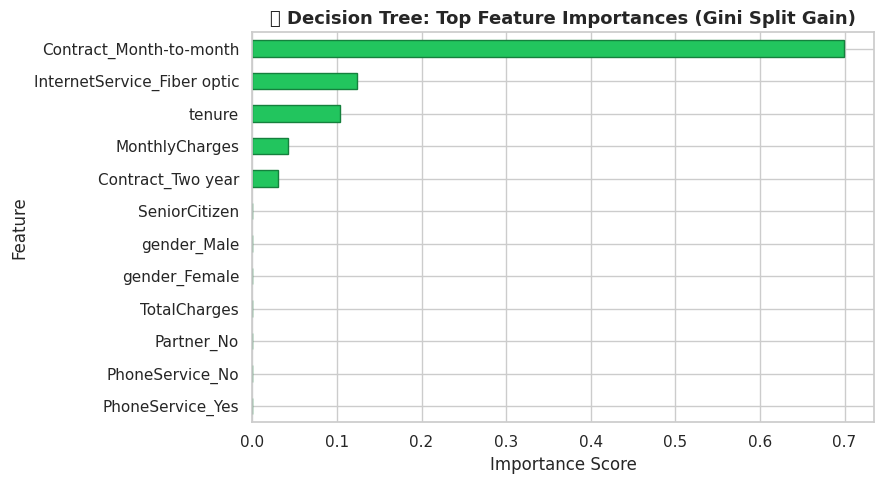

In [14]:
# 2. Decision Tree Feature Importance Bar Chart
dt_importances = pd.Series(dt_clf.feature_importances_, index=clean_feat_names).sort_values(ascending=False).head(12)

plt.figure(figsize=(9, 5))
dt_importances[::-1].plot(kind="barh", color="#22c55e", edgecolor="#15803d")
plt.title("🌿 Decision Tree: Top Feature Importances (Gini Split Gain)", fontsize=13, fontweight="bold")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("figures/dt_feature_importance.png", dpi=150)
plt.show()


### 🌲 Model 2: Random Forest — Feature Importance

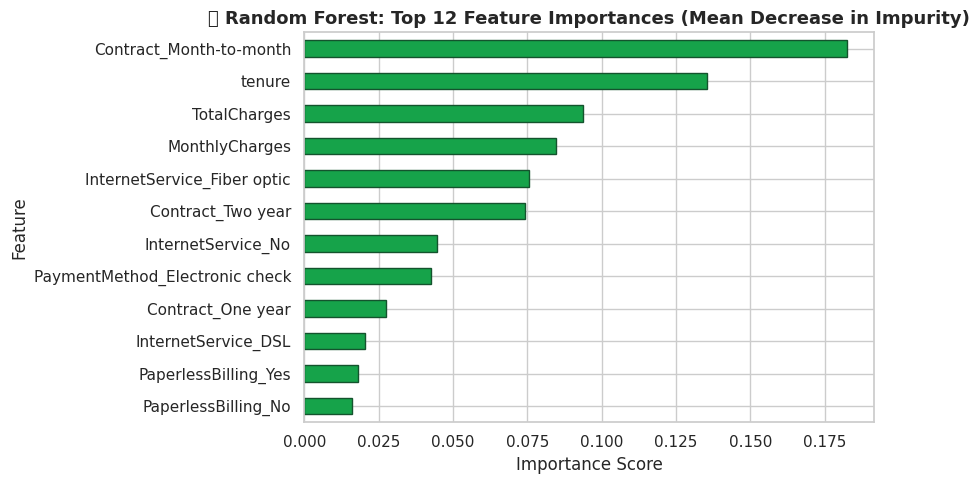

In [15]:
rf_clf = tuned["Random Forest"].named_steps["clf"]
rf_importances = pd.Series(rf_clf.feature_importances_, index=clean_feat_names).sort_values(ascending=False).head(12)

plt.figure(figsize=(9, 5))
rf_importances[::-1].plot(kind="barh", color="#16a34a", edgecolor="#14532d")
plt.title("🌲 Random Forest: Top 12 Feature Importances (Mean Decrease in Impurity)", fontsize=13, fontweight="bold")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("figures/rf_feature_importance.png", dpi=150)
plt.show()


### 📈 Model 3: Logistic Regression — Feature Coefficients (Log-Odds)

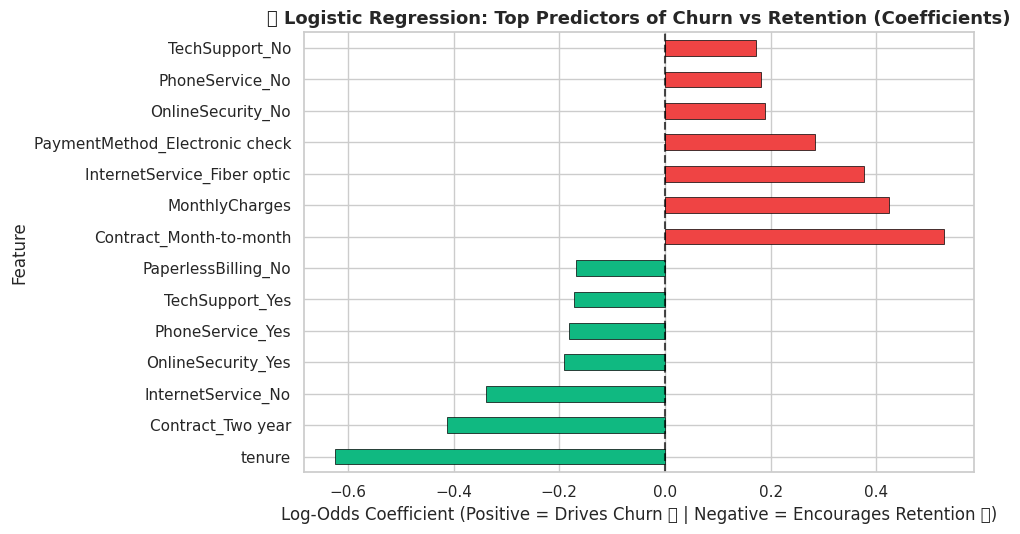

In [16]:
lr_clf = tuned["Logistic Regression"].named_steps["clf"]
lr_coef = pd.Series(lr_clf.coef_[0], index=clean_feat_names)

# Top 7 positive (risk factors) and top 7 negative (protective/retention factors)
top_pos = lr_coef.sort_values(ascending=False).head(7)
top_neg = lr_coef.sort_values(ascending=True).head(7)
combined_coef = pd.concat([top_neg, top_pos])

colors = ["#10b981" if c < 0 else "#ef4444" for c in combined_coef]

plt.figure(figsize=(10, 5.5))
combined_coef.plot(kind="barh", color=colors, edgecolor="black", linewidth=0.5)
plt.axvline(0, color="black", linestyle="--", alpha=0.7)
plt.title("📈 Logistic Regression: Top Predictors of Churn vs Retention (Coefficients)", fontsize=13, fontweight="bold")
plt.xlabel("Log-Odds Coefficient (Positive = Drives Churn 🔴 | Negative = Encourages Retention 🟢)")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("figures/lr_coefficients.png", dpi=150)
plt.show()


### 🔍 Model 4: K-Nearest Neighbors (KNN) — Permutation Feature Importance
Since KNN is a distance-based, non-parametric algorithm with no intrinsic tree splits or coefficients, **Permutation Importance** measures how much the test F1-score drops when each feature is randomly shuffled.

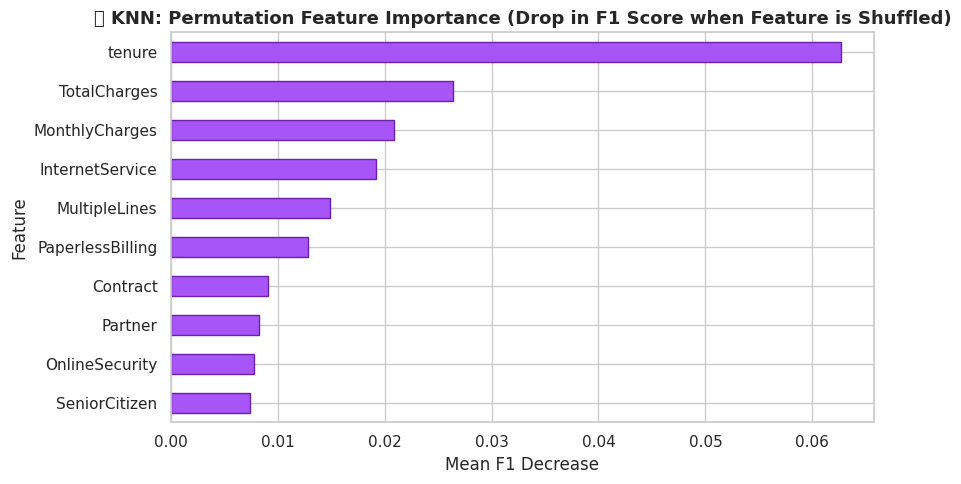

In [17]:
# Compute Permutation Feature Importance for KNN
knn_pipe = tuned["KNN"]
perm_result = permutation_importance(
    knn_pipe, X_test, y_test,
    scoring="f1", n_repeats=5, random_state=SEED, n_jobs=-1
)

# Map raw feature importances to columns in X_test
knn_importances = pd.Series(perm_result.importances_mean, index=X_test.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 5))
knn_importances[::-1].plot(kind="barh", color="#a855f7", edgecolor="#6b21a8")
plt.title("🔍 KNN: Permutation Feature Importance (Drop in F1 Score when Feature is Shuffled)", fontsize=13, fontweight="bold")
plt.xlabel("Mean F1 Decrease")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("figures/knn_permutation_importance.png", dpi=150)
plt.show()


## 7. Model Serialization for Streamlit Application

In [18]:
os.makedirs("model", exist_ok=True)

model_keys = {
    "Logistic Regression": "lr",
    "Decision Tree": "dt",
    "Random Forest": "rf",
    "KNN": "knn"
}

for name, pipe in tuned.items():
    key = model_keys[name]
    joblib.dump(pipe, f"model/{key}_model.pkl")

best_name = results_df["F1"].idxmax()
print(f"Overall Best Model (by F1): {best_name}")
print("All 4 trained pipelines successfully updated and exported to model/ directory.")


Overall Best Model (by F1): Random Forest
All 4 trained pipelines successfully updated and exported to model/ directory.
